In [1]:
from   glob     import glob
import numpy    as     np
import pandas   as     pd
import matplotlib.pyplot as     plt
from scipy import optimize


import warnings
from   astropy.io import fits
warnings.filterwarnings('ignore')

from   SNT        import normalize_spectra # https://github.com/iastro-pt/Spectra-Normalization-Tool
import loguru
loguru.logger.disable('SNT')

In [2]:
import math as m
import numpy as np
from sunsim import *

In [3]:
def vacuum2air(wv): #wv in angstroms
	wv=wv*1e-4 #A to micrometer
	a=0
	b1=5.792105e-2
	b2=1.67917e-3
	c1=238.0185
	c2=57.362

	n=1+a+b1/(c1-(1/wv**2))+b2/(c2-(1/wv**2))

	w=(wv/n)*1e4 #to Angstroms
	return w

In [4]:
### PATHS

path_data_in  = '/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/.shortcut-targets-by-id/1WjPH0zd5VocfpASpJ6hkrfTrENlZi8jh/Sun Mask/Data/Input/'
path_data_out = '/Users/sophiestucki/Documents/poet/output/'
path_figs     = '/Users/sophiestucki/Documents/poet/figures/'

#%%
### VALD

# VALD columns
cols = [
'species'      , # species
'wave'         , # central wavelength
'loggf'        , # log oscillator strength
'E_l'          , # excitation lower
'J_l'          , # ionization lower
'E_u'          , # excitation upper
'J_u'          , # ionization upper
'lande_l'      , # lande g lower
'lande_u'      , # lande g upper
'lande_m'      , # lande g mean
'damping_rad'  , # damping radiative
'damping_stark', # damping stark
'damping_waals', # damping waals
'depth_vald'     # central depth
]
Ncol = len(cols)

# Find VALD files
files_vald = sorted(glob(path_data_in+'SUN_ESPRESSO_VALD.txt'))
Nfile_vald = len(files_vald)

# VALD DataFrame
df_vald = np.zeros(Nfile_vald, dtype=object)

# Loop VALD files
for k in range(Nfile_vald):

    # Read VALD file
    with open(files_vald[k]) as f:
        rows = f.readlines()

    # Nr. of spectral lines
    Nline = int(rows[0].split(',')[2])

    # VALD array
    arr_vald = np.zeros((Nline,Ncol), dtype=object)

    # Loop lines
    for i in range(Nline):

        # Jump rows
        j = 3+4*i

        # Split row
        row = rows[j].split(',')

        # Extract line parameters
        arr_vald[i,0] = str(row[ 0])[1:-1]
        for c in range(1,Ncol):
            arr_vald[i,c] = float(row[c])
    
    # Save line parameters
    df_vald[k] = arr_vald

# Merge line parameters
df_vald = pd.concat([pd.DataFrame(df_vald[k], columns=cols) for k in range(Nfile_vald)]).reset_index(drop=True)

#%%
### SAVE

# Save as CSV file
df_vald.to_csv(path_data_out+'SUN_LINELIST_VALD.csv', index=False)

#%%

In [5]:
# Extract wavelengths and contrasts
# weight = contrast **2 , sum(weight) = N_line
hdul = fits.open(path_data_in+'SUN_ESPRESSO_MASK.fits')
wave = hdul[1].data['lambda'  ]
cont = hdul[1].data['contrast']
hdul.close()

#%%
### SAVE

# Save as CSV file
df = pd.DataFrame()
df['wave'] = wave
df['cont'] = cont
df.to_csv(path_data_out+'SUN_LINELIST_MASK.csv', index=False)

#%%

In [6]:
def compute_ccf_params(rv,ccf,plot_test):
    '''
    Compute the parameters of the CCF and its bisector span 
    (10-40% bottom minus 60-90% top)
    '''
    rvs=np.zeros(len(ccf)) #initialize
    fwhm=np.zeros(len(ccf))
    contrast=np.zeros(len(ccf))
    BIS=np.zeros(len(ccf))
    #bisector F/F_c
    raw_xbis = []
    raw_ybis = []


    for i in range(len(ccf)): #loop for each ccf
        # if self.ccf_norm == 1:
        #     print('CCF shifted to 0.0')
        ccf[i] = ccf[i] - ccf[i].min() + 0.000001
        #Compute bisector and remove wings
        cutleft0,cutright0,xbis,ybis=nbspectra.speed_bisector_nb(rv,ccf[i]/ccf[i].max(),integrated_bis=True) #FAST
        # cutleft0,cutright0,xbis,ybis=nbspectra.speed_bisector_nb(rv,ccf[i],integrated_bis=True) #test


        raw_xbis.append(xbis)
        raw_ybis.append(ybis)
        BIS[i]=np.mean(xbis[np.array(ybis>=0.1) & np.array(ybis<=0.4)])-np.mean(xbis[np.array(ybis<=0.9) & np.array(ybis>=0.6)]) #FAST
        if i==0:
            cutleft,cutright=cutleft0,cutright0
        try:
            popt,_=optimize.curve_fit(nbspectra.gaussian2, rv[cutleft:cutright], ccf[i][cutleft:cutright],p0=[np.max(ccf[i][cutleft:cutright]),rv[cutleft:cutright][np.argmax(ccf[i][cutleft:cutright])]+100,1.5*2052.903741094618+1000,0.000001]) #fit a gaussian
        except:
            popt=[1.0,100000.0,1,100000.0]
        contrast[i]=popt[0] #amplitude
        rvs[i]=popt[1] #mean
        fwhm[i]=2*m.sqrt(2*np.log(2))*np.abs(popt[2]) #fwhm relation to std

        if plot_test: 
            plt.plot(rv,1-ccf[i]/ccf[i].max())
            plt.plot(xbis,1-ybis,'b')
            plt.show(block=True)


    return rvs, contrast, fwhm, BIS, raw_xbis, raw_ybis

In [7]:
rv = 1e3*np.arange(-18,18.25, 0.25) #m/s

mask = fits.open('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/.shortcut-targets-by-id/1WjPH0zd5VocfpASpJ6hkrfTrENlZi8jh/Sun Mask/Data/Input/SUN_ESPRESSO_MASK.fits')
wvm = mask[1].data['lambda']
fm = mask[1].data['contrast']


In [91]:
def continuum(mask, fwhm):
    """Continuum of the part of the spectrum selected by mask."""
    return normalize_spectra(
        wavelengths  =wave_p[mask],
        spectra      =flux_p[mask],
        FWHM_override=fwhm,
        header={},
        output_path='',
        store_to_disk=False,
        fname=''
    )[0]

In [122]:
# Read PoET spectrum
hdul = fits.open(path_data_in+'r.ESPRE.2026-04-06T16:12:11.991_S1D_A.fits')
wave_p = hdul[1].data  ['wavelength_air'          ].astype('float64')
flux_p = hdul[1].data  ['flux'                    ].astype('float64')
fwhm_p = hdul[0].header['HIERARCH ESO QC CCF FWHM']
hdul.close()

#%%
### CONTINUUM NORMALIZATION

# Continuum normalization, done separately below and above cut_wave, then merged
cut_wave = 4200.0      # [A] the spectrum is cut here
overlap = 0.0          # [A] each part is fitted up to this distance beyond the cut (to avoid edge effects); 0 = exact cut


blue = (wave_p < cut_wave)
red = ~blue
cont_blue = continuum(wave_p < cut_wave + overlap, 0.5)      # blue part (+ overlap)
# cont_red = continuum(wave_p >= cut_wave - overlap, 1.4)      # red part (+ overlap)

# merge: each continuum is used only on its own side of the cut
cont_p = np.empty_like(flux_p)
cont_p[blue] = cont_blue[:np.sum(blue)]
cont_p[red] = cont_red[-np.sum(red):]

#%%
# ### SAVE
# f_p = flux_p/cont_p
# ccf_p = nbspectra.cross_correlation_mask(np.asarray(rv, dtype=np.float64), np.asarray(wave_p, dtype=np.float64), np.asarray(f_p, dtype=np.float64), np.asarray(wvm, dtype=np.float64), np.asarray(fm, dtype=np.float64), 'mps', False)
# rv_p, _, fwhm_p, bis_p, x_bis_p, y_bis_p = compute_ccf_params(rv,[ccf_p],True)

# wv_p_shifted = wave_p * (1 - rv_p[0]/2.99792458e8)

# # Save as CSV file
# df_p = pd.DataFrame()
# df_p['wave'] = wv_p_shifted
# df_p['flux'] = flux_p/cont_p
# df_p.to_csv(path_data_out+'SUN_SPECTRUM_POET.csv', index=False)

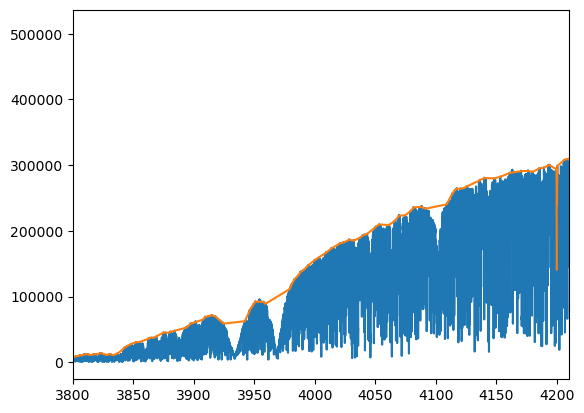

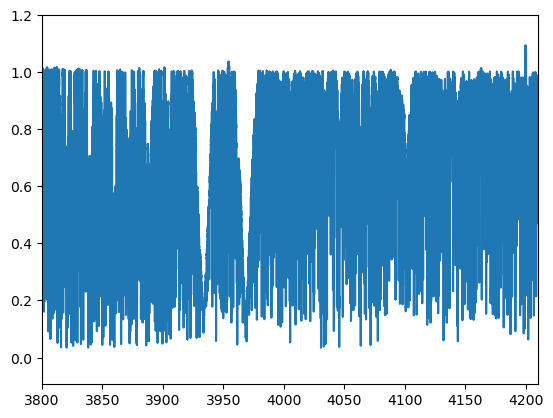

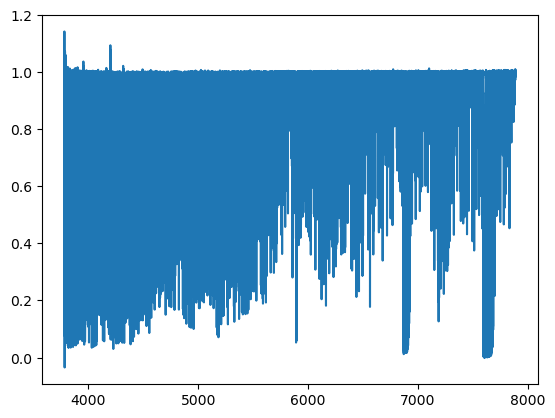

In [147]:
plt.plot(wave_p, flux_p)
plt.plot(wave_p, cont_p)
# plt.axvline(x=cut_wave)
plt.xlim(3800,4210)

plt.show()
plt.xlim(3800,4210)
plt.plot(wave_p, flux_p/cont_p)
plt.show()
plt.plot(wave_p, flux_p/cont_p)


In [136]:
data = np.load('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/.shortcut-targets-by-id/1WjPH0zd5VocfpASpJ6hkrfTrENlZi8jh/Sun Mask/Data/Input/disk_integrated_quiet_muram.npy', allow_pickle=True).item()
wave = data['wav']
flux = data['flux']

#%%
### CONTINUUM NORMALIZATION

# Continuum normalization, done separately below and above cut_wave, then merged (as for PoET)
cut_wave = 4200.0      # [A] the spectrum is cut here
overlap = 5.0          # [A] each part is fitted up to this distance beyond the cut: SNT leaves NaN at the edges
                       # of the part it fits, so with 0 the continuum is NaN right at the cut
fwhm_blue =    0.1    # FWHM for the blue part
fwhm_red = 0.5        # FWHM for the red part

def continuum_muram(mask, fwhm_part):
    """Continuum of the part of the MURaM spectrum selected by mask."""
    return normalize_spectra(
        wavelengths  =wave[mask],
        spectra      =flux[mask],
        FWHM_override=fwhm_part,
        header={},
        output_path='',
        store_to_disk=False,
        fname=''
    )[0]

blue = (wave < cut_wave)
red = ~blue
cont_blue = continuum_muram(wave < cut_wave + overlap, fwhm_blue)      # blue part (+ overlap)
cont_red = continuum_muram(wave >= cut_wave - overlap, fwhm_red)       # red part (+ overlap)

# merge: each continuum is used only on its own side of the cut
cont = np.empty_like(flux, dtype=np.float64)
cont[blue] = cont_blue[:np.sum(blue)]
cont[red] = cont_red[-np.sum(red):]

#%%
### SAVE
# f = flux/cont
# ccf = nbspectra.cross_correlation_mask(np.asarray(rv, dtype=np.float64), np.asarray(wave, dtype=np.float64), np.asarray(f, dtype=np.float64), np.asarray(wvm, dtype=np.float64), np.asarray(fm, dtype=np.float64), 'mps', False)
# rvs, _, fwhm, bis, x_bis, y_bis = compute_ccf_params(rv,[ccf],True)

# wv_shifted = wave * (1 - rvs[0]/2.99792458e8)

# # Save as CSV file
# df = pd.DataFrame()
# df['wave'] = wv_shifted
# df['flux'] = flux/cont
# df.to_csv(path_data_out+'SUN_SPECTRUM_MURAM.csv', index=False)

#%%

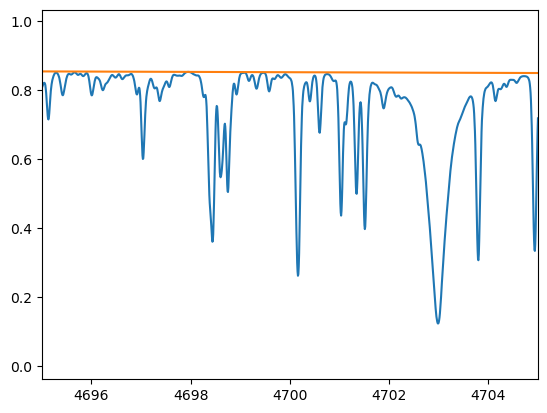

(4695.0, 4705.0)

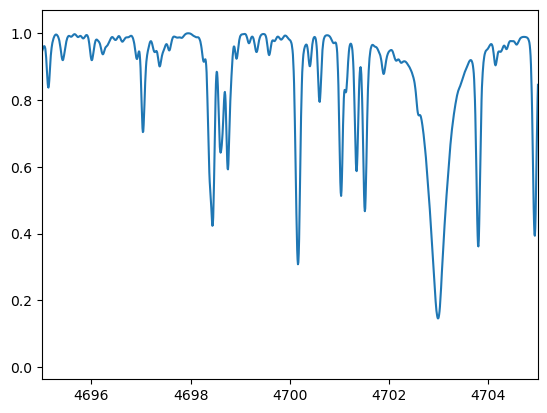

In [146]:
plt.plot(wave, flux)
plt.plot(wave, cont)
plt.xlim(4695,4705)

plt.show()
plt.plot(wave, flux/cont)

plt.xlim(4695,4705)

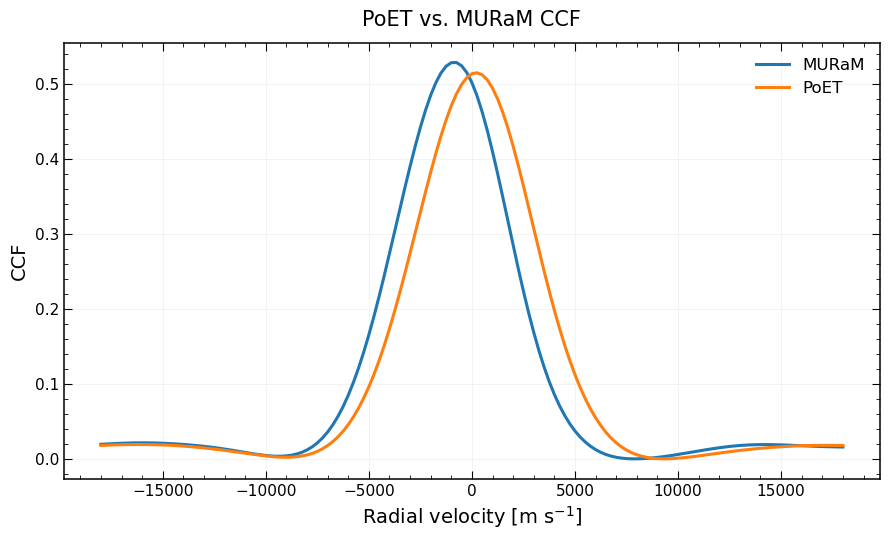

In [21]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(rv, ccf, lw=2.2, label='MURaM', zorder=3)
ax.plot(rv, ccf_p, lw=2.2, label='PoET', zorder=3)

ax.set_xlabel(r'Radial velocity [m s$^{-1}$]', fontsize=14)
ax.set_ylabel('CCF', fontsize=14)
ax.set_title('PoET vs. MURaM CCF', fontsize=15, pad=12)

ax.legend(frameon=False, fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
ax.minorticks_on()

ax.grid(alpha=0.15, linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig(path_figs+'Fig_CCFs.png', bbox_inches='tight', dpi=1000)
plt.show()


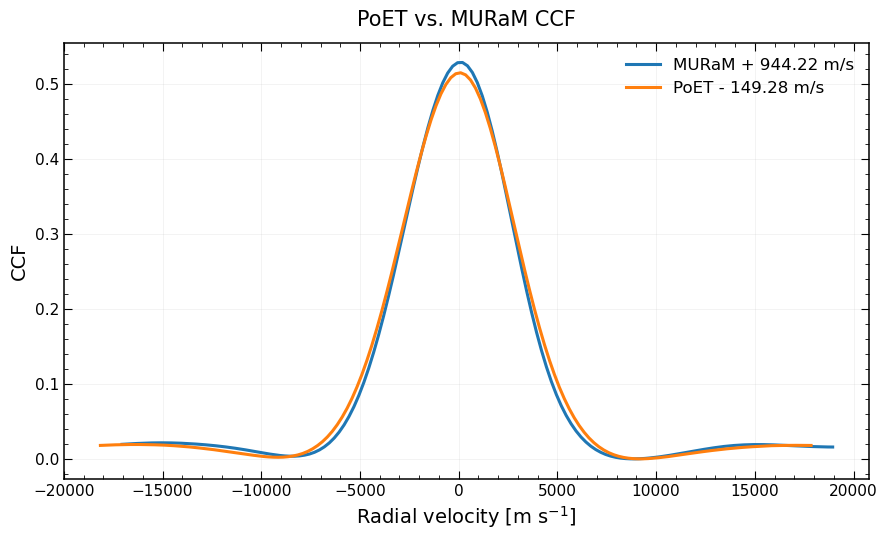

In [22]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(rv+944.22099141, ccf, lw=2.2, label='MURaM + 944.22 m/s', zorder=3)
ax.plot(rv-149.28181995, ccf_p, lw=2.2, label='PoET - 149.28 m/s', zorder=3)

ax.set_xlabel(r'Radial velocity [m s$^{-1}$]', fontsize=14)
ax.set_ylabel('CCF', fontsize=14)
ax.set_title('PoET vs. MURaM CCF', fontsize=15, pad=12)

ax.legend(frameon=False, fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
ax.minorticks_on()

ax.grid(alpha=0.15, linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig(path_figs+'Fig_CCFs_shifted.png', bbox_inches='tight', dpi=1000)
plt.show()

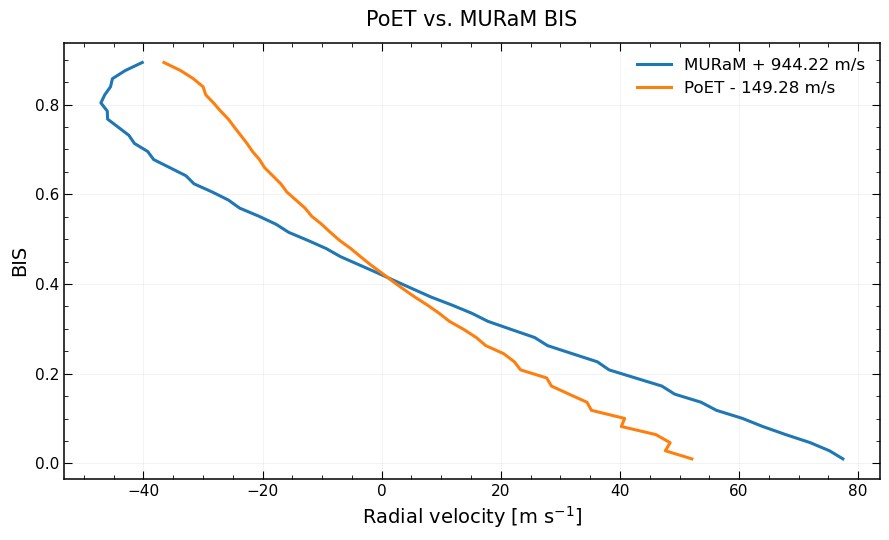

In [23]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(x_bis[0]+944.22099141, 1-y_bis[0], lw=2.2, label='MURaM + 944.22 m/s', zorder=3)
ax.plot(x_bis_p[0]-149.28181995, 1-y_bis[0], lw=2.2, label='PoET - 149.28 m/s', zorder=3)

ax.set_xlabel(r'Radial velocity [m s$^{-1}$]', fontsize=14)
ax.set_ylabel('BIS', fontsize=14)
ax.set_title('PoET vs. MURaM BIS', fontsize=15, pad=12)

ax.legend(frameon=False, fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=11, direction='in', top=True, right=True, length=6)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, length=3)
ax.minorticks_on()

ax.grid(alpha=0.15, linewidth=0.7)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.savefig(path_figs+'Fig_BIS_shifted.png', bbox_inches='tight', dpi=1000)
plt.show()

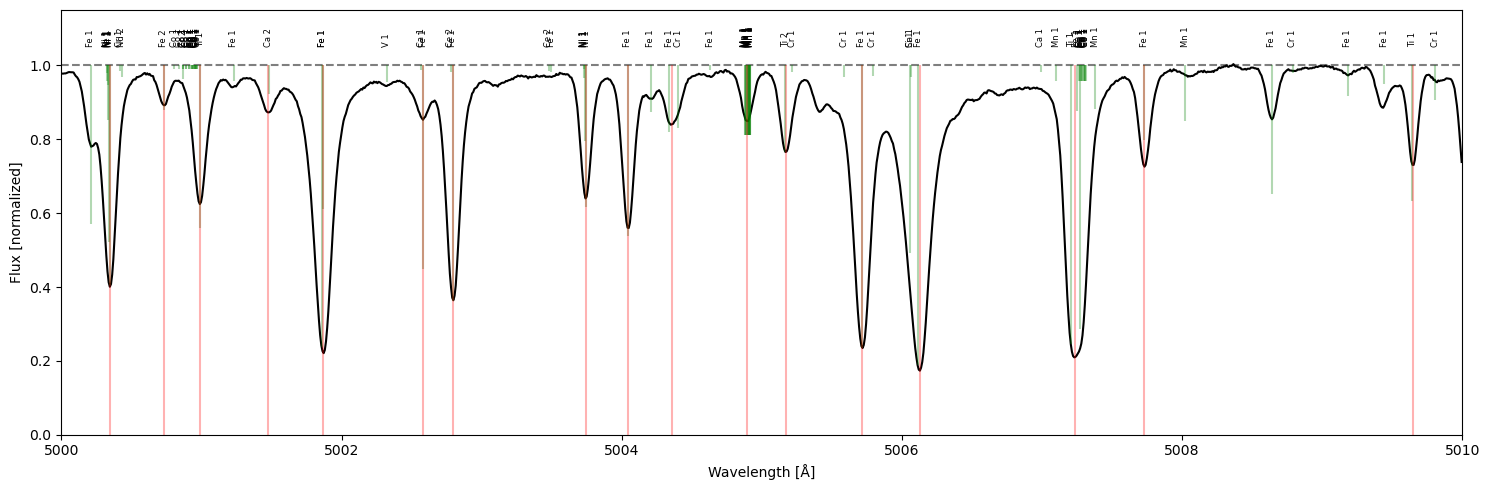

In [24]:
# Read VALD linelist
df_vald_p = pd.read_csv(path_data_out+'SUN_LINELIST_VALD.csv')
Nline_vald_p = len(df_vald_p)

# Read MASK linelist
df_mask_p = pd.read_csv(path_data_out+'SUN_LINELIST_MASK.csv')
Nline_mask_p = len(df_mask_p)

#%%
### PLOT

# Read PoET spectrum
df_p = pd.read_csv(path_data_out+'SUN_SPECTRUM_POET.csv')
wave_p = df_p['wave'].values
flux_p = df_p['flux'].values

# Plot limit
wave_min_p = 5000
wave_max_p = 5010

# Index of pixels within plot limit
idx_spec_p = (wave_p>=wave_min_p) & (wave_p<=wave_max_p)

# Index of VALD lines within plot limit
idx_line_vald_p = (df_vald_p['wave']>=wave_min_p) & (df_vald_p['wave']<=wave_max_p)

# Index of MASK lines within plot limit
idx_line_mask_p = (df_mask_p['wave']>=wave_min_p) & (df_mask_p['wave']<=wave_max_p)

# Plot solar spectrum and lines
plt.figure(figsize=(15,5))
plt.plot(wave_p[idx_spec_p], flux_p[idx_spec_p], '-k')
plt.axhline(1, color='k', ls='--', alpha=0.5)
for i in range(Nline_vald_p):
    if idx_line_vald_p[i]:
        plt.vlines(df_vald_p['wave'][i], ymin=1-df_vald_p['depth_vald'][i], ymax=1, color='g', alpha=0.3)
        plt.text(df_vald_p['wave'][i], 1.05, df_vald_p['species'][i], rotation=90, verticalalignment='bottom', horizontalalignment='center', fontsize=6)
for i in range(Nline_mask_p):
    if idx_line_mask_p[i]:
        plt.vlines(df_mask_p['wave'][i], ymin=0, ymax=1, color='r', alpha=0.3)
plt.xlabel('Wavelength [Å]')
plt.ylabel('Flux [normalized]')
plt.xlim(wave_min_p, wave_max_p)
plt.ylim(0, 1.15)
plt.tight_layout()
plt.savefig(path_figs+'Fig_1.png', bbox_inches='tight', dpi=1000)

#%%

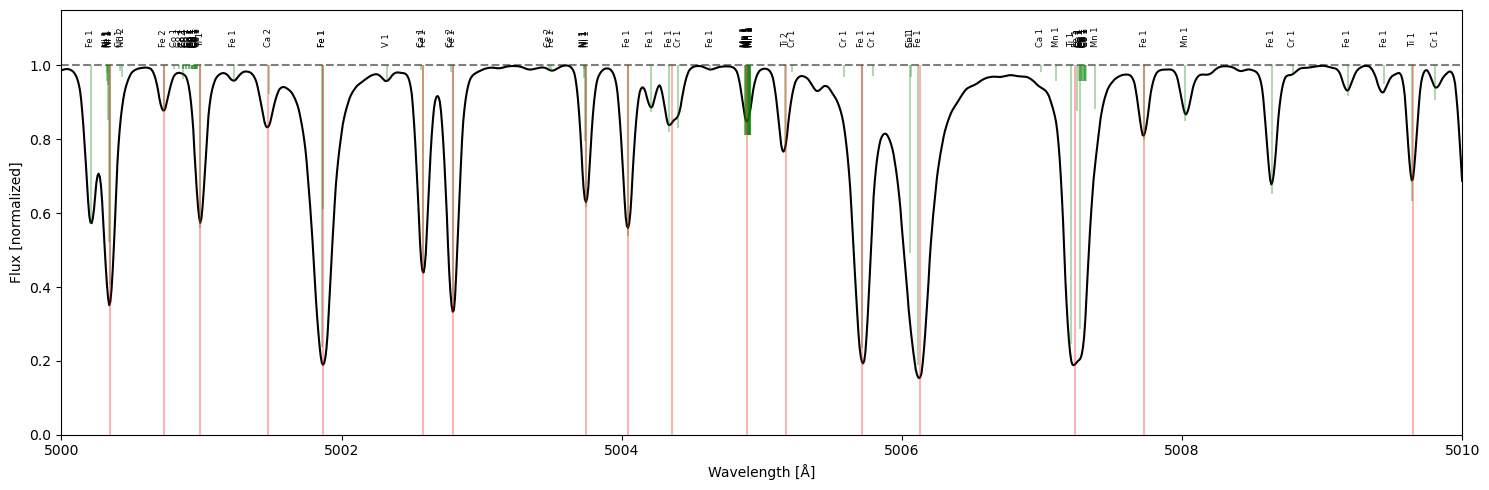

In [25]:
# Read VALD linelist
df_vald = pd.read_csv(path_data_out+'SUN_LINELIST_VALD.csv')
Nline_vald = len(df_vald)

# Read MASK linelist
df_mask = pd.read_csv(path_data_out+'SUN_LINELIST_MASK.csv')
Nline_mask = len(df_mask)

#%%
### PLOT

# Read MURAM spectrum
df = pd.read_csv(path_data_out+'SUN_SPECTRUM_MURAM.csv')
wave = df['wave'].values
flux = df['flux'].values

# Plot limit
wave_min = 5000
wave_max = 5010

# Index of pixels within plot limit
idx_spec = (wave>=wave_min) & (wave<=wave_max)

# Index of VALD lines within plot limit
idx_line_vald = (df_vald['wave']>=wave_min) & (df_vald['wave']<=wave_max)

# Index of MASK lines within plot limit
idx_line_mask = (df_mask['wave']>=wave_min) & (df_mask['wave']<=wave_max)

# Plot solar spectrum and lines
plt.figure(figsize=(15,5))
plt.plot(wave[idx_spec], flux[idx_spec], '-k')
plt.axhline(1, color='k', ls='--', alpha=0.5)
for i in range(Nline_vald):
    if idx_line_vald[i]:
        plt.vlines(df_vald['wave'][i], ymin=1-df_vald['depth_vald'][i], ymax=1, color='g', alpha=0.3)
        plt.text(df_vald['wave'][i], 1.05, df_vald['species'][i], rotation=90, verticalalignment='bottom', horizontalalignment='center', fontsize=6)
for i in range(Nline_mask):
    if idx_line_mask[i]:
        plt.vlines(df_mask['wave'][i], ymin=0, ymax=1, color='r', alpha=0.3)
plt.xlabel('Wavelength [Å]')
plt.ylabel('Flux [normalized]')
plt.xlim(wave_min, wave_max)
plt.ylim(0, 1.15)
plt.tight_layout()
plt.savefig(path_figs+'Fig_1_MURAM.png', bbox_inches='tight', dpi=1000)

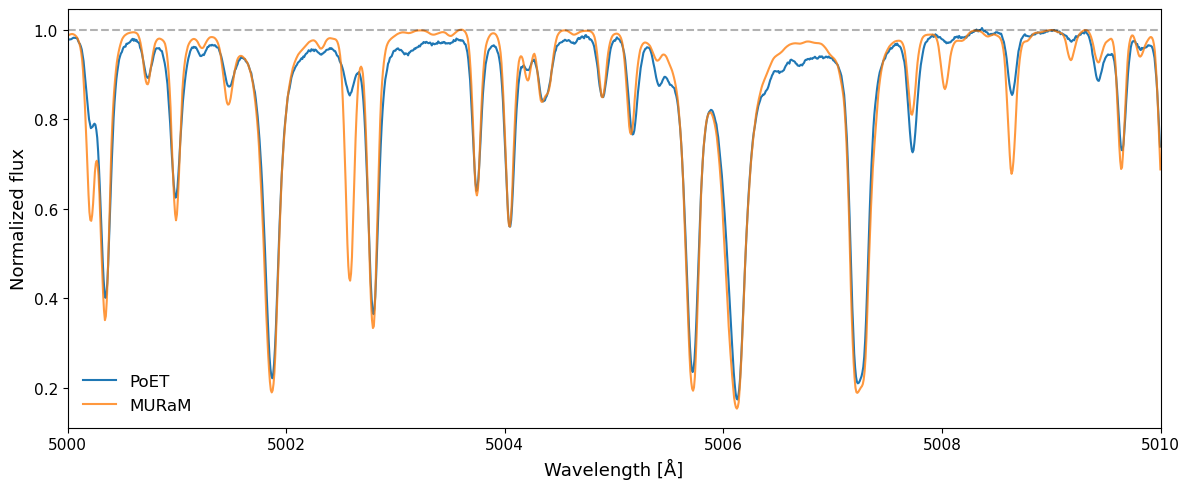

In [26]:
plt.figure(figsize=(12,5))
plt.plot(wave_p[idx_spec_p], flux_p[idx_spec_p], label='PoET', lw=1.5)
plt.plot(wave[idx_spec], flux[idx_spec], label='MURaM', lw=1.5, alpha=0.8)
plt.axhline(1, color='k', ls='--', alpha=0.3)
plt.xlabel('Wavelength [Å]', fontsize=13)
plt.ylabel('Normalized flux', fontsize=13)
plt.xlim(wave_min, wave_max)
plt.tick_params(axis='both', labelsize=11)
plt.legend(frameon=False, fontsize=12)
plt.tight_layout()
# plt.savefig(path_figs+'Fig_1_PoET_vs_MURAM.png', bbox_inches='tight', dpi=1000)

plt.show()

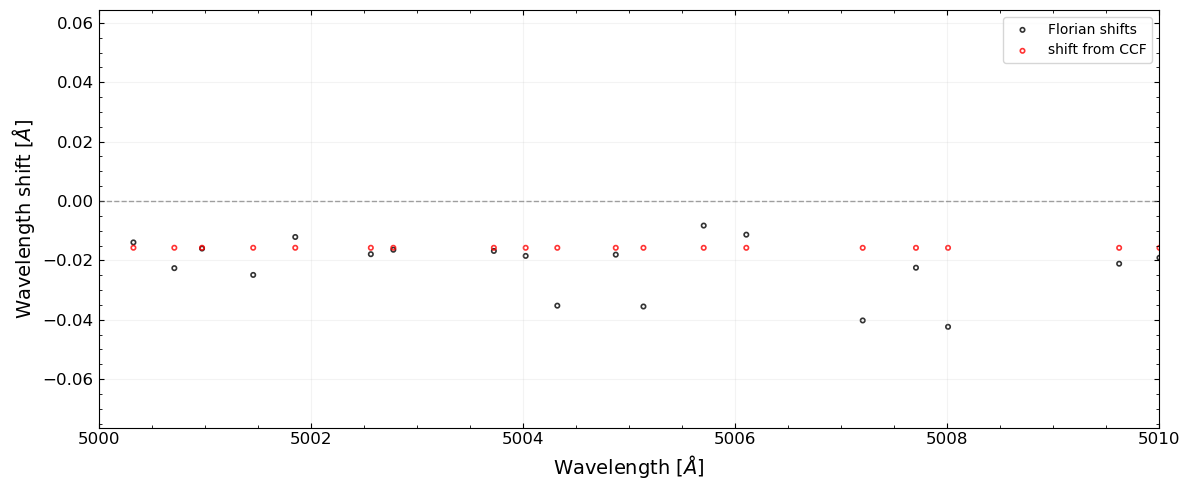

In [29]:
mask_shift_flo = np.loadtxt('/Users/sophiestucki/Downloads/HARPS_mask_nm_QS-aligned(08.01.2026).txt')

wv_s = vacuum2air(mask_shift_flo[:,0]*10)
fm_s = mask_shift_flo[:,2]*10


plt.figure(figsize=(12,5))
plt.scatter(wv_s, fm_s, s=10, facecolors='none', edgecolors='k', linewidths=1.2, alpha=0.8, label='Florian shifts')
plt.scatter(wv_s, wv_s * (rvs[0] / 2.99792458e8), s=10, facecolors='none', edgecolors='r', linewidths=1.2, alpha=0.8, label='shift from CCF')

plt.axhline(0, color='0.4', linestyle='--', linewidth=1, alpha=0.6)
plt.xlabel(r'Wavelength [$\AA$]', fontsize=14)
plt.ylabel(r'Wavelength shift [$\AA$]', fontsize=14)
plt.xlim(5000,5010)
plt.tick_params(axis='both', which='major', labelsize=12, direction='in', top=True, right=True)
plt.minorticks_on()
plt.tick_params(axis='both', which='minor', direction='in', top=True, right=True)
plt.grid(alpha=0.15)
plt.tight_layout()
plt.legend()
plt.savefig(path_figs+'shift_MURAM_wv_5000-5010.png', bbox_inches='tight', dpi=1000)

plt.show()

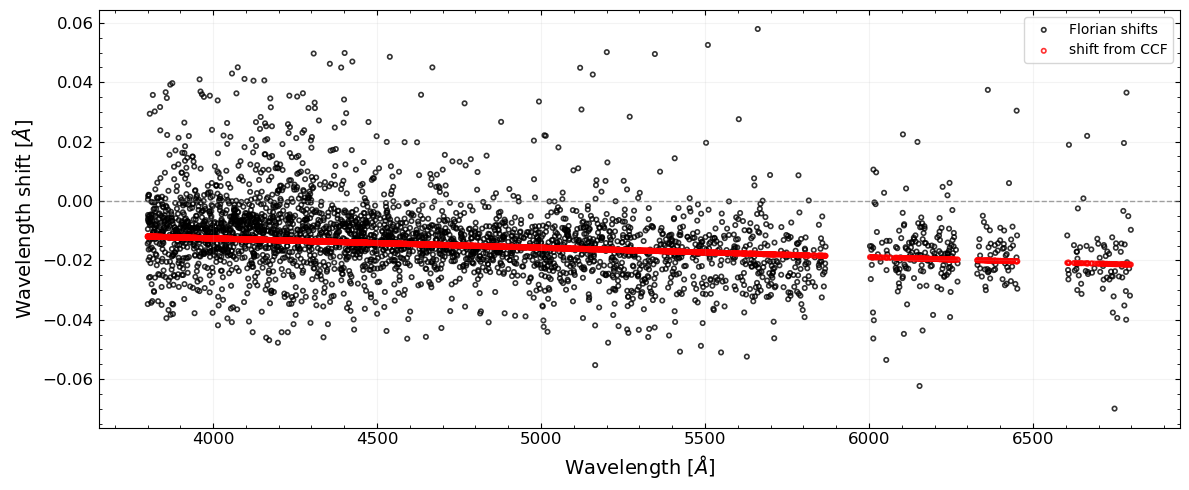

In [31]:
plt.figure(figsize=(12,5))
plt.scatter(wv_s, fm_s, s=10, facecolors='none', edgecolors='k', linewidths=1.2, alpha=0.8, label='Florian shifts')
plt.scatter(wv_s, wv_s * (rvs[0] / 2.99792458e8), s=10, facecolors='none', edgecolors='r', linewidths=1.2, alpha=0.8, label='shift from CCF')
plt.axhline(0, color='0.4', linestyle='--', linewidth=1, alpha=0.6)
plt.xlabel(r'Wavelength [$\AA$]', fontsize=14)
plt.ylabel(r'Wavelength shift [$\AA$]', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12, direction='in', top=True, right=True)
plt.minorticks_on()
plt.tick_params(axis='both', which='minor', direction='in', top=True, right=True)
plt.grid(alpha=0.15)
plt.tight_layout()
plt.legend()
plt.savefig(path_figs+'shift_MURAM_wv.png', bbox_inches='tight', dpi=1000)

plt.show()

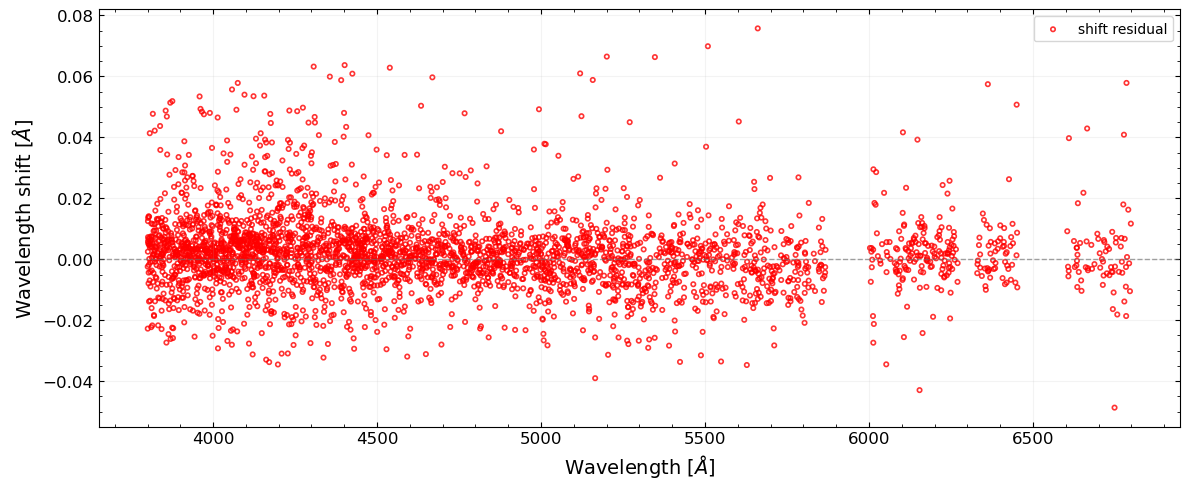

In [32]:
plt.figure(figsize=(12,5))
plt.scatter(wv_s, fm_s - wv_s * (rvs[0] / 2.99792458e8), s=10, facecolors='none', edgecolors='r', linewidths=1.2, alpha=0.8, label='shift residual')
plt.axhline(0, color='0.4', linestyle='--', linewidth=1, alpha=0.6)
plt.xlabel(r'Wavelength [$\AA$]', fontsize=14)
plt.ylabel(r'Wavelength shift [$\AA$]', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12, direction='in', top=True, right=True)
plt.minorticks_on()
plt.tick_params(axis='both', which='minor', direction='in', top=True, right=True)
plt.grid(alpha=0.15)
plt.tight_layout()
plt.legend()
plt.savefig(path_figs+'shiftres_MURAM_wv.png', bbox_inches='tight', dpi=1000)

plt.show()